# Parte 1 — Introdução, descrição dos dados e exploração inicial

Nesta parte apresentamos o contexto e os objetivos do trabalho, descrevemos o conjunto de dados e analisamos estatísticas descritivas, valores extremos e correlações. As interpretações do trabalho original acompanham os respetivos gráficos.

# **Trabalho Prático Programação para a Ciência de Dados**

O crescimento exponencial da utilização de dispositivos eletrónicos, nomeadamente de 
smartphones, transformou o modo que as pessoas interagem, trabalham e vivem. O 
aumento do tempo de ecrã, notificações constantes e a dependência do smartphone 
tem sido associados ao aumento da ansiedade, pior qualidade de sono, diminuição da 
capacidade de foco, menor produtividade e um maior risco de burnout. A relevância 
deste tema, incide na necessidade urgente de compreender a correlação entre o tempo 
e o modo como de como utilizamos a tecnologia e a saúde mental.

## Descrição do dataset

In [ ]:
import pandas as pd
data = pd.read_csv("data/dataset_prog.csv", sep=";")

print (data.describe())

                id          age  device_hours_per_day  phone_unlocks  \
count  3500.000000  3500.000000           3500.000000    3500.000000   
mean   1750.500000    28.078571              7.317677     147.107429   
std    1010.507298     9.352385              3.239838      67.770656   
min       1.000000    13.000000              0.280000       9.000000   
25%     875.750000    21.000000              4.867500      96.000000   
50%    1750.500000    27.000000              6.760000     136.000000   
75%    2625.250000    34.000000              9.152500     187.000000   
max    3500.000000    50.000000             17.160000     374.000000   

       notifications_per_day  social_media_mins   study_mins  \
count            3500.000000        3500.000000  3500.000000   
mean              335.117143         159.362857   108.116571   
std               239.678612         132.748048    79.796273   
min                22.000000           0.000000     0.000000   
25%               170.000000   

A idade média dos participantes é de 28 anos, com valores entre 13 e 50, indicando que estamos perante um grupo predominantemente jovem. A utilização diária dos dispositivos apresenta uma média de 7,3 horas, evidenciando um comportamento digital intenso. O número médio de desbloqueios por dia foi cerca de 147 e o número de notificações foi 335, ambos apresentam elevada variabilidade, influenciada pela presença de utilizadores com níveis de atividade substancialmente superiores ao restante grupo.
Em termos de bem-estar e estilo de vida, os participantes dormem, em média, 7,25 horas por noite e praticam atividade física cerca de 3 dias por semana. Os indicadores de saúde mental, como ansiedade, depressão e stress, apresentam médias moderadas, mas com máximos elevados, sugerindo a existência de utilizadores em situação de maior vulnerabilidade psicológica. A pontuação de felicidade apresenta grande variabilidade, enquanto a produtividade média se situa por volta dos 65 pontos. Cerca de 20% da amostra está sinalizada como “alto risco”, reforçando a pertinência do estudo da relação entre comportamento digital e bem-estar mental.
A análise descritiva mostra uma grande variabilidade nos comportamentos digitais dos participantes. O tempo diário de ecrã e o número de desbloqueios apresentam desvios-padrão elevados, indicando que existem utilizadores com hábitos muito distintos, desde um uso reduzido até consumos bastante intensivos. O tempo passado em redes sociais segue o mesmo padrão, revelando perfis muito diferentes de utilização. Já o digital_dependence_score apresenta variabilidade moderada, sugerindo diferenças entre participantes, mas menos extremas do que nas restantes variáveis digitais.
No que diz respeito ao bem-estar psicológico, tanto os níveis de ansiedade como de depressão apresentam elevada variabilidade, mostrando que os participantes têm estados emocionais muito diferentes entre si. Em contraste, as horas de sono exibem baixa dispersão, indicando um padrão relativamente consistente de descanso. No conjunto, estes resultados sugerem que os comportamentos digitais são bastante diversificados, enquanto alguns indicadores de bem-estar são mais estáveis.
Numa visão global, o dataset apresenta-se completo, coerente ao nível dos tipos de dados. A presença de outliers revelou-se natural e informativa, não justificando correções. As estatísticas descritivas permitem ter uma noção inicial dos padrões de comportamento digital e do bem-estar mental na população estudada, servindo como base para as análises seguintes.

## Boxplot de outliers

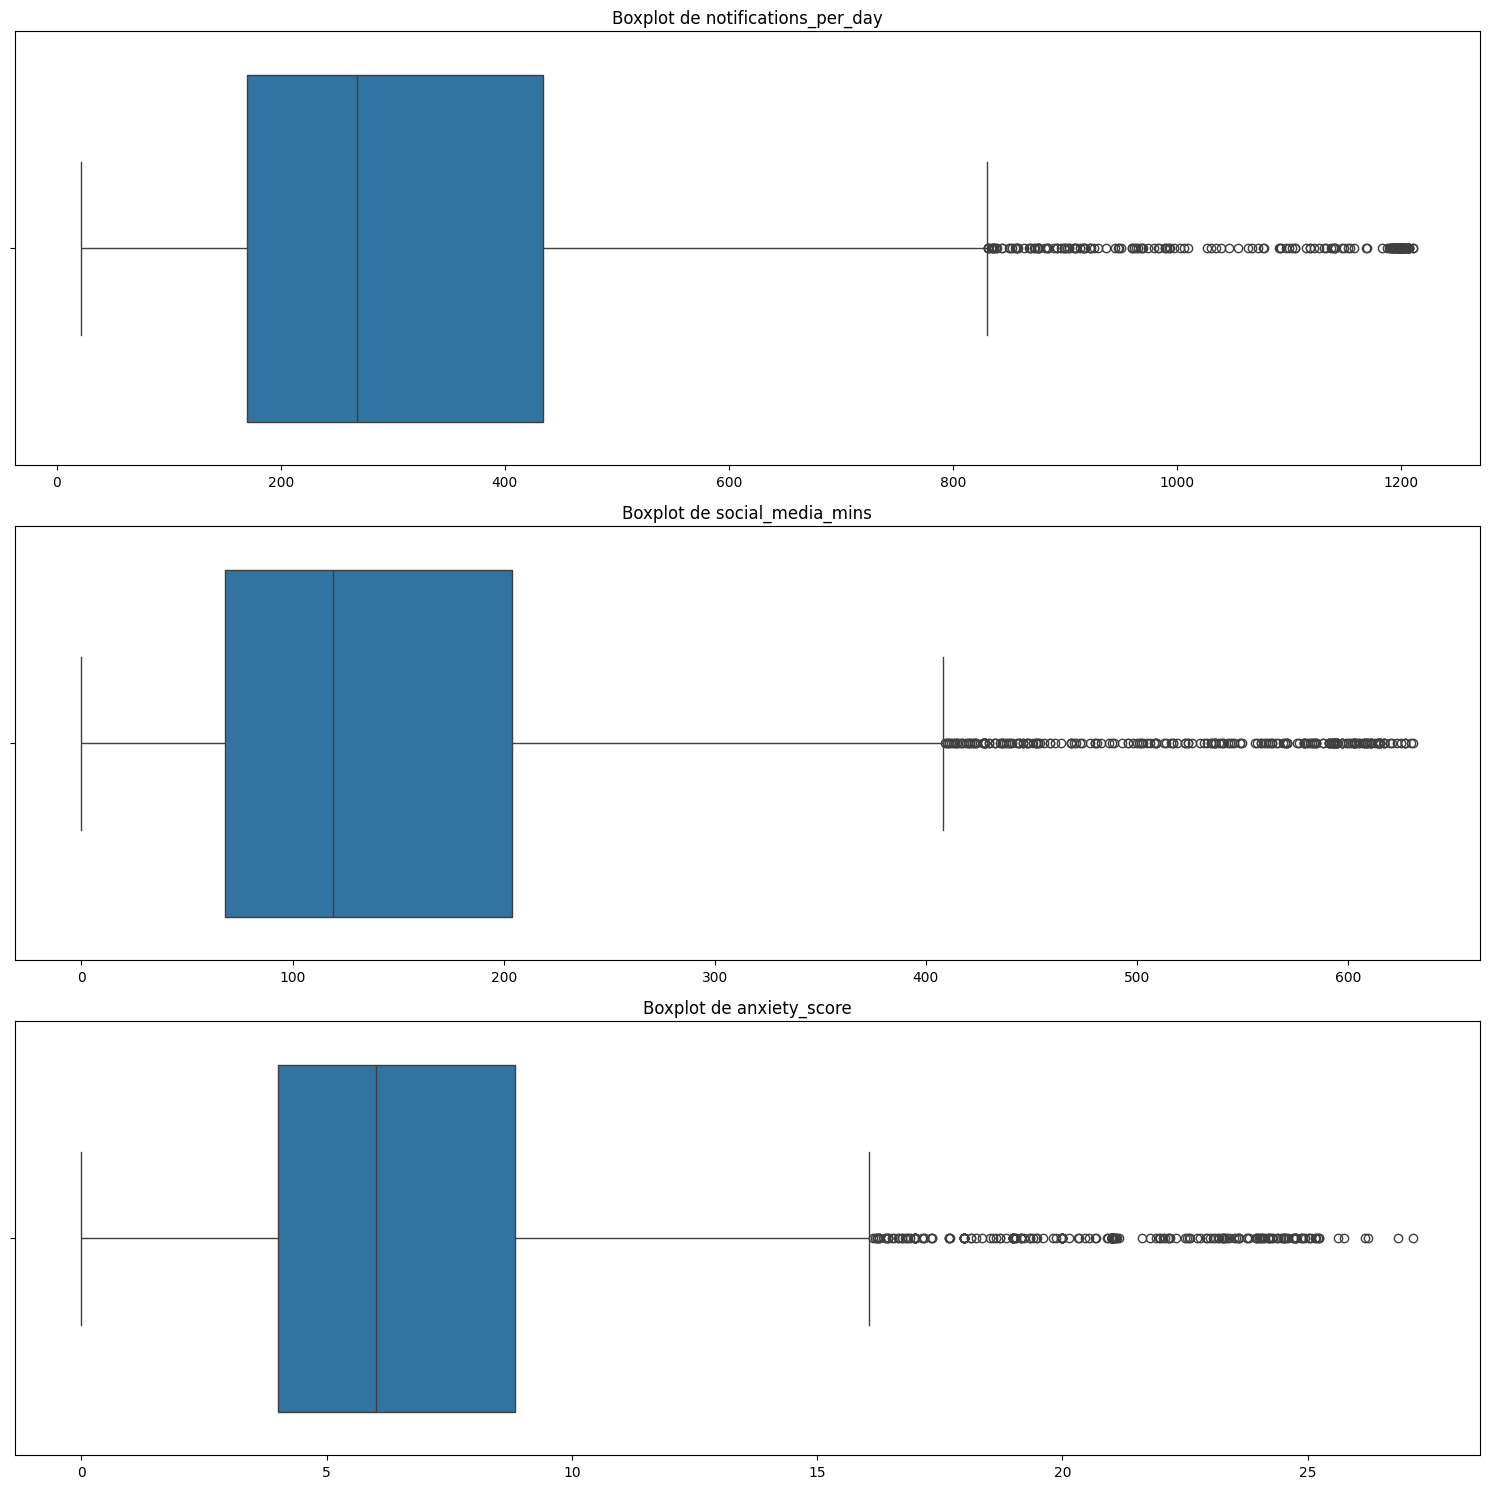

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

numeric_cols = ['notifications_per_day', 'social_media_mins', 'anxiety_score']

plt.figure(figsize=(15, 5 * len(numeric_cols)))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=data[col])
    plt.title(f"Boxplot de {col}")
    plt.xlabel("")

plt.tight_layout()
plt.show()

Os boxplots revelaram a existência de vários valores acima do limite superior, o que indica outliers estatísticos.
No entanto, ao analisar o contexto das variáveis, verificou-se que é plausível que alguns utilizadores recebam entre 500 e 1000 notificações por dia, especialmente utilizadores muito ativos nas redes sociais. Também é natural que existam indivíduos que passam muitas horas diárias em plataformas digitais. Os valores elevados de ansiedade são igualmente coerentes com realidades clínicas de parte da população.
Apesar da presença de outliers, estes parecem representar situações reais e coerentes com o comportamento humano, como utilizadores muito ativos no telemóvel ou em redes sociais. Assim, optou-se por manter todas as observações no dataset para preservar a variabilidade original dos dados.

## Clustermap - correlação entre as variáveis digitais e psicológicas

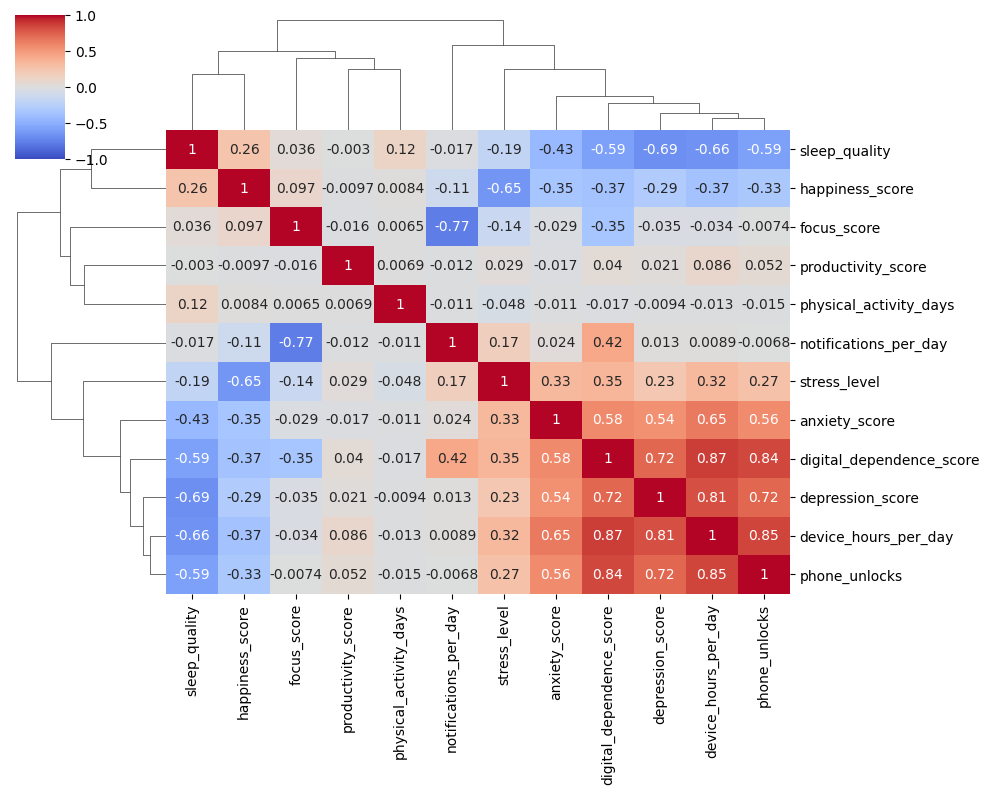

In [ ]:
data = pd.read_csv("data/dataset_prog.csv", sep=";")

corr_dig_psi = [
    'device_hours_per_day','phone_unlocks','notifications_per_day',
    'digital_dependence_score','sleep_quality','anxiety_score',
    'depression_score','stress_level','happiness_score','focus_score',
    'productivity_score', 'physical_activity_days'
]

corr_matrix = data[corr_dig_psi].corr()

sns.clustermap(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    annot=True,
    figsize=(10,8)
)

plt.show()

No clustermap, é possível identificar dois grandes grupos de variáveis, um associado ao uso digital intensivo e a mal-estar psicológico (horas de ecrã, desbloqueios, dependência digital, stress, ansiedade e depressão), e outro associado ao bem-estar (qualidade de sono, felicidade e foco).
Em relação ao primeiro grupo, podemos averiguar que existem correlações fortes e positivas, tais como dependência digital - ansiedade (r = 0.87), dependência digital ↔ stress (r= 0.58) e horas de ecrã - desbloqueios (r= 0.85). Com isto, podemos concluir que quanto maior é a intensidade do comportamento digital, maiores tendem a ser os níveis de stress, ansiedade e sintomas depressivos.
 Já em relação ao segundo grupo, podemos constatar que possui correlações negativas fortes, tais como foco - notificações (r= -0.77), qualidade de sono - ansiedade (r= -0.43) e felicidade - stress (r= -0.65). Assim, podemos concluir que quanto mais inconsequente é o uso digital, pior é a qualidade do sono, foco e a felicidade.
Por fim, podemos ainda averiguar duas variáveis que possuem uma fraca ligação em relação às restantes. Sendo estas, o nível de produtividade, as notificações recebidas por dia e os dias de atividade física. Isto indica que apresentam correlações muito fracas, próximas de zero, com a maioria das outras variáveis, sugerindo pouca ou nenhuma relação linear direta no conjunto de dados.